# Global Petroleum Consumption, Fuel Prices & Economic Analysis

## Project objective
Integrate the supplied country-level petroleum datasets, validate data quality, enrich country records with geographic identifiers, and explore consumption, reported fuel prices, and GDP per capita.

**Important limitation:** These are cross-sectional data. The analysis describes associations and differences; it does not establish causation or trends over time.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pycountry
from countryinfo import CountryInfo

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
CHART_DIR = ROOT / "visualizations"
CHART_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /mnt/data/petroleum_portfolio_verified


## 1. Load the source datasets

In [2]:
path1, path2 = DATA_DIR / "Petrol1.csv", DATA_DIR / "Petrol2.csv"
missing = [str(p) for p in (path1, path2) if not p.exists()]
if missing:
    raise FileNotFoundError("Missing source file(s): " + ", ".join(missing))
petrol1 = pd.read_csv(path1, encoding="cp1252").copy()
petrol2 = pd.read_csv(path2, encoding="cp1252").copy()
print("Petrol1 shape:", petrol1.shape)
print("Petrol2 shape:", petrol2.shape)
display(petrol1.head(3), petrol2.head(3))

Petrol1 shape: (181, 8)
Petrol2 shape: (181, 11)


,#,Country,Daily Oil Consumption (Barrels),World Share,Yearly Gallons Per Capita,Price Per Gallon (USD),Price Per Liter (USD),Price Per Liter (PKR)
0,1,United States,19687287,20.30%,934.3,5.19,1.37,289.97
1,2,China,12791553,13.20%,138.7,5.42,1.43,302.87
2,3,India,4443000,4.60%,51.4,5.05,1.33,281.93


,S#,Country,Daily Oil Consumption (Barrels),World Share,Yearly Gallons Per Capita,Price Per Gallon (USD),Price Per Liter (USD),Price Per Liter (PKR),GDP Per Capita ( USD ),Gallons GDP Per Capita Can Buy,xTimes Yearly Gallons Per Capita Buy
0,1,United States,"19,687,287",20%,934.3,5.19,1.37,289.97,"63,414","12,218",13
1,2,China,"12,791,553",13%,138.7,5.42,1.43,302.87,"10,435","1,925",14
2,3,India,"4,443,000",5%,51.4,5.05,1.33,281.93,"1,901",376,7


## 2. Validate country keys and merge
The merge uses consumption/pricing fields from `Petrol1.csv` and economic affordability fields from `Petrol2.csv`. Country keys are stripped before the one-to-one merge.

In [3]:
for label, frame in [("Petrol1", petrol1), ("Petrol2", petrol2)]:
    if "Country" not in frame.columns:
        raise KeyError(f"{label} is missing the Country column")
    frame["Country"] = frame["Country"].astype("string").str.strip()
    if frame["Country"].isna().any() or frame["Country"].eq("").any():
        raise ValueError(f"{label} contains missing/empty country names")
    if frame["Country"].duplicated().any():
        raise ValueError(f"{label} contains duplicate country keys")

consumption_cols = ["Country", "Daily Oil Consumption (Barrels)", "World Share",
                    "Yearly Gallons Per Capita", "Price Per Gallon (USD)",
                    "Price Per Liter (USD)"]
economic_cols = ["Country", "GDP Per Capita ( USD )",
                 "Gallons GDP Per Capita Can Buy", "xTimes Yearly Gallons Per Capita Buy"]
for label, frame, cols in [("Petrol1", petrol1, consumption_cols), ("Petrol2", petrol2, economic_cols)]:
    absent = sorted(set(cols) - set(frame.columns))
    if absent:
        raise KeyError(f"{label} missing expected columns: {absent}")

pet = petrol1[consumption_cols].merge(
    petrol2[economic_cols], on="Country", how="outer", validate="one_to_one", indicator=True
)
print("Merge indicator counts:\n", pet["_merge"].value_counts().to_string())
pet = pet.drop(columns="_merge")
pet = pet.rename(columns={
    "Country": "country_name",
    "Daily Oil Consumption (Barrels)": "daily_oil_barrels",
    "World Share": "world_share_pct",
    "Yearly Gallons Per Capita": "yearly_gallons_per_capita",
    "Price Per Gallon (USD)": "price_per_gallon_usd",
    "Price Per Liter (USD)": "price_per_liter_usd",
    "GDP Per Capita ( USD )": "gdp_per_capita_usd",
    "Gallons GDP Per Capita Can Buy": "gallons_gdp_per_capita_can_buy",
    "xTimes Yearly Gallons Per Capita Buy": "affordability_multiple"
})
pet["country_name"] = pet["country_name"].astype("string").str.strip()
numeric_fields = [c for c in pet.columns if c != "country_name"]
for col in numeric_fields:
    cleaned = (pet[col].astype("string").str.strip()
               .str.replace(",", "", regex=False)
               .str.replace("%", "", regex=False))
    pet[col] = pd.to_numeric(cleaned, errors="coerce")
display(pet.head())
print("Merged dataset shape:", pet.shape)

Merge indicator counts:
 _merge
both          181
left_only       0
right_only      0


,country_name,daily_oil_barrels,world_share_pct,yearly_gallons_per_capita,price_per_gallon_usd,price_per_liter_usd,gdp_per_capita_usd,gallons_gdp_per_capita_can_buy,affordability_multiple
0,Afghanistan,35000,0.04,15.2,3.62,0.96,509,141,9
1,Albania,27000,0.03,143.4,8.0,2.11,5215,652,5
2,Algeria,429000,0.4,162.2,1.18,0.31,3310,2805,17
3,Angola,133000,0.1,70.7,1.39,0.37,1896,1364,19
4,Argentina,709000,0.7,249.8,3.96,1.05,8579,2166,9


Merged dataset shape: (181, 9)


## 3. Geographic enrichment
Use country metadata to assign ISO-3 codes and continents. A short alias dictionary handles common source-name variants. Unresolved names are retained and reported rather than silently assigned.

In [4]:
# Geographic enrichment: library lookup first, then reviewed fallbacks for dataset-specific names.
# ISO alpha-3 codes follow ISO 3166-1; see the UN Statistics Division M49 country/area list.
ALIASES = {
    "United States of America": "United States",
    "Czech Republic (Czechia)": "Czechia",
    "Czech Republic": "Czechia",
    "South Korea": "Korea, Republic of",
    "North Korea": "Korea, Democratic People's Republic of",
    "Russia": "Russian Federation",
    "Iran": "Iran, Islamic Republic of",
    "Vietnam": "Viet Nam",
    "Syria": "Syrian Arab Republic",
    "Tanzania": "Tanzania, United Republic of",
    "Bolivia": "Bolivia, Plurinational State of",
    "Venezuela": "Venezuela, Bolivarian Republic of",
    "Moldova": "Moldova, Republic of",
    "Brunei": "Brunei Darussalam",
    "Laos": "Lao People's Democratic Republic",
    "Ivory Coast": "Côte d'Ivoire",
    "Palestine": "State of Palestine",
}

# Explicit reviewed fallback for country/territory labels not consistently handled by CountryInfo.
# The dataset label is retained; these values only enrich the geographic fields.
GEO_FALLBACKS = {
    "South Korea": ("KOR", "Asia"),
    "Iran": ("IRN", "Asia"),
    "Venezuela": ("VEN", "South America"),
    "Vietnam": ("VNM", "Asia"),
    "Czech Republic (Czechia)": ("CZE", "Europe"),
    "Myanmar": ("MMR", "Asia"),
    "Bolivia": ("BOL", "South America"),
    "Tanzania": ("TZA", "Africa"),
    "Côte d'Ivoire": ("CIV", "Africa"),
    "State of Palestine": ("PSE", "Asia"),
    "North Macedonia": ("MKD", "Europe"),
    "Bahamas": ("BHS", "North America"),
    "North Korea": ("PRK", "Asia"),
    "Moldova": ("MDA", "Europe"),
    "Congo": ("COG", "Africa"),
    "Macao": ("MAC", "Asia"),
    "Brunei": ("BRN", "Asia"),
    "Montenegro": ("MNE", "Europe"),
    "Cabo Verde": ("CPV", "Africa"),
    "Gambia": ("GMB", "Africa"),
    "British Virgin Islands": ("VGB", "North America"),
    "Saint Pierre & Miquelon": ("SPM", "North America"),
}

REGION_TO_CONTINENT = {
    "Africa": "Africa", "Asia": "Asia", "Europe": "Europe",
    "Oceania": "Oceania", "Americas": "Americas"
}

def geo_for_country(country):
    raw_name = str(country).strip()
    name = ALIASES.get(raw_name, raw_name)
    iso3 = pd.NA
    continent = pd.NA
    try:
        iso3 = pycountry.countries.lookup(name).alpha_3
    except LookupError:
        pass
    try:
        info = CountryInfo(name).info()
        iso3 = info.get("ISO", {}).get("alpha3", iso3)
        continent = REGION_TO_CONTINENT.get(info.get("region"), pd.NA)
    except Exception:
        pass
    fallback = GEO_FALLBACKS.get(raw_name)
    if fallback:
        fallback_iso3, fallback_continent = fallback
        if pd.isna(iso3):
            iso3 = fallback_iso3
        if pd.isna(continent):
            continent = fallback_continent

    # CountryInfo uses the broad "Americas" region. Normalize those records to
    # North America or South America for consistent continent-level comparisons.
    SOUTH_AMERICA = {
        "Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Ecuador",
        "Guyana", "Paraguay", "Peru", "Suriname", "Uruguay", "Venezuela"
    }
    NORTH_AMERICA = {
        "Aruba", "Bahamas", "Barbados", "Belize", "British Virgin Islands",
        "Canada", "Cayman Islands", "Costa Rica", "Cuba", "Dominica",
        "Dominican Republic", "El Salvador", "Grenada", "Guatemala", "Haiti",
        "Honduras", "Jamaica", "Mexico", "Montserrat", "Nicaragua", "Panama",
        "Puerto Rico", "Saint Pierre & Miquelon", "Trinidad and Tobago", "United States"
    }
    if raw_name in SOUTH_AMERICA:
        continent = "South America"
    elif raw_name in NORTH_AMERICA:
        continent = "North America"
    return pd.Series({"iso3": iso3, "continent": continent})

geo = pet["country_name"].apply(geo_for_country)
pet[["iso3", "continent"]] = geo[["iso3", "continent"]]
unresolved_geo = pet.loc[pet["iso3"].isna() | pet["continent"].isna(),
                         ["country_name", "iso3", "continent"]]
print("Unresolved geographic classifications:", len(unresolved_geo))
display(unresolved_geo)
print("Continent counts:\n", pet["continent"].value_counts(dropna=False).to_string())


Unresolved geographic classifications: 0


,country_name,iso3,continent


Continent counts:
 continent
Asia             49
Africa           46
Europe           40
North America    25
South America    12
Oceania           9


## 4. Data quality checks

In [5]:
assert pet["country_name"].notna().all(), "Country names must not be missing"
assert pet["country_name"].is_unique, "Country names must be unique"
for col in ["daily_oil_barrels", "price_per_gallon_usd", "price_per_liter_usd", "gdp_per_capita_usd"]:
    negative_count = int(pet[col].dropna().lt(0).sum())
    print(f"Negative values in {col}: {negative_count}")
print("\\nMissing values by field:\\n", pet.isna().sum().to_string())
price_gap = (pet["price_per_gallon_usd"] - pet["price_per_liter_usd"] * 3.785411784).abs()
print("\\nMedian absolute gallon/liter price discrepancy:", round(price_gap.median(), 3))
print("Largest gallon/liter price discrepancy:", round(price_gap.max(), 3))
print("\\nData types:\\n", pet.dtypes.to_string())

Negative values in daily_oil_barrels: 0
Negative values in price_per_gallon_usd: 0
Negative values in price_per_liter_usd: 0
Negative values in gdp_per_capita_usd: 0
\nMissing values by field:\n country_name                      0
daily_oil_barrels                 0
world_share_pct                   0
yearly_gallons_per_capita         0
price_per_gallon_usd              0
price_per_liter_usd               0
gdp_per_capita_usd                0
gallons_gdp_per_capita_can_buy    0
affordability_multiple            0
iso3                              0
continent                         0
\nMedian absolute gallon/liter price discrepancy: 0.008
Largest gallon/liter price discrepancy: 0.024
\nData types:\n country_name                      string[python]
daily_oil_barrels                          Int64
world_share_pct                          Float64
yearly_gallons_per_capita                Float64
price_per_gallon_usd                     Float64
price_per_liter_usd                      Float

## 5. Exploratory analysis and visualizations

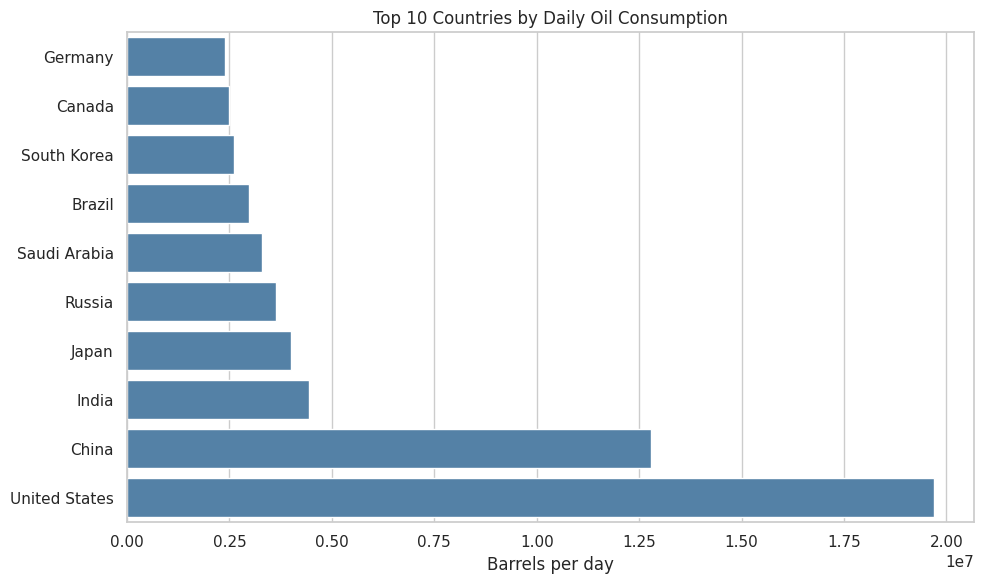

,country_name,daily_oil_barrels,world_share_pct
60,Germany,2383393,2.5
31,Canada,2486301,2.6
148,South Korea,2605440,2.7
22,Brazil,2984000,3.1
138,Saudi Arabia,3302000,3.4
134,Russia,3631287,3.7
80,Japan,4012877,4.1
72,India,4443000,4.6
35,China,12791553,13.2
172,United States,19687287,20.3


In [6]:
# Chart 1: Top 10 countries by daily oil consumption
top = pet.dropna(subset=["daily_oil_barrels"]).nlargest(10, "daily_oil_barrels").sort_values("daily_oil_barrels")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top, x="daily_oil_barrels", y="country_name", ax=ax, color="steelblue")
ax.set(title="Top 10 Countries by Daily Oil Consumption", xlabel="Barrels per day", ylabel="")
plt.tight_layout()
fig.savefig(CHART_DIR / "top_10_oil_consumption.png", dpi=160, bbox_inches="tight")
plt.show()
display(top[["country_name", "daily_oil_barrels", "world_share_pct"]])

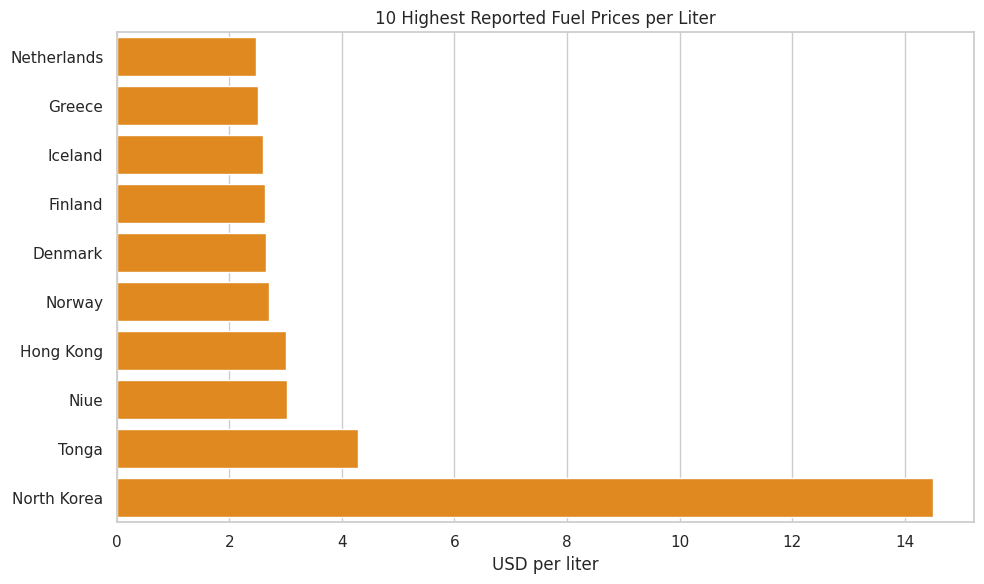

,country_name,price_per_liter_usd
113,Netherlands,2.47
62,Greece,2.51
71,Iceland,2.6
55,Finland,2.64
46,Denmark,2.65
121,Norway,2.7
69,Hong Kong,3.0
118,Niue,3.02
163,Tonga,4.28
119,North Korea,14.5


In [7]:
# Chart 2: Highest reported fuel prices per liter
top_price = pet.dropna(subset=["price_per_liter_usd"]).nlargest(10, "price_per_liter_usd").sort_values("price_per_liter_usd")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top_price, x="price_per_liter_usd", y="country_name", ax=ax, color="darkorange")
ax.set(title="10 Highest Reported Fuel Prices per Liter", xlabel="USD per liter", ylabel="")
plt.tight_layout()
fig.savefig(CHART_DIR / "highest_fuel_prices.png", dpi=160, bbox_inches="tight")
plt.show()
display(top_price[["country_name", "price_per_liter_usd"]])

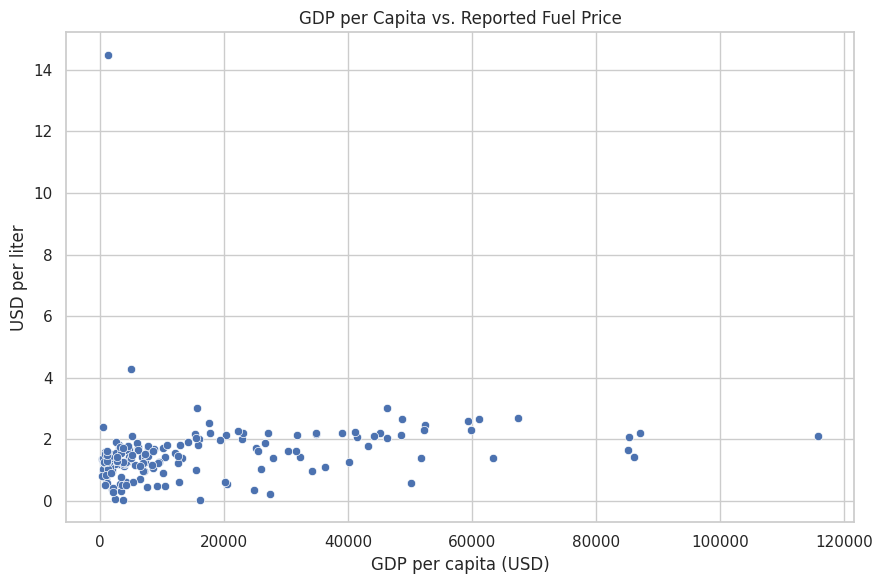

Spearman rank correlation: 0.429 (association only; not evidence of causation)


In [8]:
# Chart 3: GDP per capita versus reported fuel price
subset = pet.dropna(subset=["gdp_per_capita_usd", "price_per_liter_usd"])
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=subset, x="gdp_per_capita_usd", y="price_per_liter_usd", ax=ax)
ax.set(title="GDP per Capita vs. Reported Fuel Price", xlabel="GDP per capita (USD)", ylabel="USD per liter")
plt.tight_layout()
fig.savefig(CHART_DIR / "gdp_vs_fuel_price.png", dpi=160, bbox_inches="tight")
plt.show()
if len(subset) >= 3:
    print("Spearman rank correlation:", round(subset["gdp_per_capita_usd"].corr(subset["price_per_liter_usd"], method="spearman"), 3),
          "(association only; not evidence of causation)")

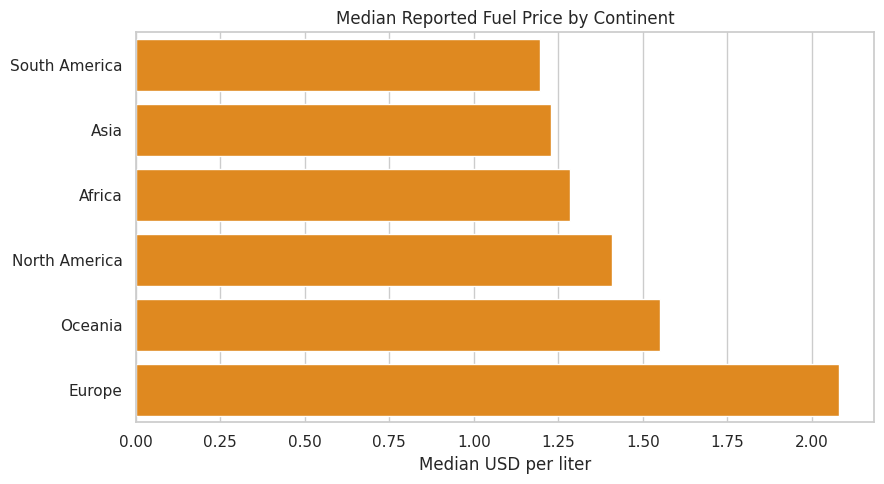

,continent,median_price_usd_per_liter,countries
0,Africa,1.285,46
1,Asia,1.23,49
2,Europe,2.08,40
3,North America,1.41,25
4,Oceania,1.55,9
5,South America,1.195,12


In [9]:
# Chart 4: Median fuel price by continent (only mapped records)
region = (pet.dropna(subset=["continent", "price_per_liter_usd"])
          .groupby("continent", as_index=False)
          .agg(median_price_usd_per_liter=("price_per_liter_usd", "median"),
               countries=("country_name", "nunique")))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=region.sort_values("median_price_usd_per_liter"),
            x="median_price_usd_per_liter", y="continent", ax=ax, color="darkorange")
ax.set(title="Median Reported Fuel Price by Continent", xlabel="Median USD per liter", ylabel="")
plt.tight_layout()
fig.savefig(CHART_DIR / "regional_median_fuel_prices.png", dpi=160, bbox_inches="tight")
plt.show()
display(region)

## 6. Data-derived summary
The following statements are calculated from the loaded data. Confirm source dates, definitions, and provenance before presenting them as market conclusions.

In [10]:
eligible = pet.dropna(subset=["daily_oil_barrels"])
if not eligible.empty:
    leader = eligible.loc[eligible["daily_oil_barrels"].idxmax()]
    print(f"Largest reported daily oil consumption: {leader['country_name']} ({leader['daily_oil_barrels']:,.0f} barrels/day).")
price_eligible = pet.dropna(subset=["price_per_liter_usd"])
if not price_eligible.empty:
    print(f"Median reported fuel price across {len(price_eligible)} countries: ${price_eligible['price_per_liter_usd'].median():.2f}/liter.")
if not region.empty:
    high = region.loc[region["median_price_usd_per_liter"].idxmax()]
    print(f"Highest median regional price among mapped records: {high['continent']} (${high['median_price_usd_per_liter']:.2f}/liter; n={int(high['countries'])}).")
print("Interpretation caution: these are descriptive cross-sectional summaries, not causal estimates or time trends.")

Largest reported daily oil consumption: United States (19,687,287 barrels/day).
Median reported fuel price across 181 countries: $1.40/liter.
Highest median regional price among mapped records: Europe ($2.08/liter; n=40).
Interpretation caution: these are descriptive cross-sectional summaries, not causal estimates or time trends.
